<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/VQNN_NetworkAttack_Gong2022.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# VQNN for network attack detection: Gong, Guan, Gani and Qi (2022) step by step

This notebook re-implements, runs and checks the method of

> Changqing Gong, Weiqi Guan, Abdullah Gani and Han Qi, "Network attack detection scheme based on variational quantum
> neural network", *The Journal of Supercomputing* 78:16876-16897, 2022. DOI 10.1007/s11227-022-04542-z.

The paper publishes no code. Everything below is written from the paper's description (Sections 3 and 4, Figs. 7 and 8,
Tables 1 to 7). The authors used **TensorFlow Quantum + Cirq**, which cannot be installed on current Colab or on this
machine; the circuit is therefore rebuilt **gate for gate in PennyLane** (exact state-vector simulation, autograd + Adam)
and, for the "real IBM device" experiment, in Qiskit with the noise models of the six fake IBM 5-qubit devices the paper names.

**What the notebook does.** It downloads the KDD Cup 1999 data (10 % file), draws the paper's balanced subset
(700 training + 300 test connections), keeps the paper's five features (Table 2), encodes them into a 5-qubit circuit
(Hadamard + `Rz(-2 pi x)`), trains the paper's 8-layer variational circuit (`Rz Ry Rz` rotations + CNOT chain per layer)
with Adam (learning rate 0.01), and checks every number the paper reports: the depth sweep of Table 3, the comparison
with ANN / SVM / KNN / NB / DT of Table 5, and the IBM-hardware confusion matrix of Table 7 (emulated with device noise
models, because no hardware is used). It also runs a **de-duplicated** variant, because KDD99 is full of exact duplicate
records and the paper does not say how it handled them.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. With `FAST_MODE = True` the whole notebook takes a few
minutes; `FAST_MODE = False` runs the full depth sweep 1 to 10 over several seeds (see the configuration cell for the
exact budgets and timings). No Hugging Face token, GPU or IBM account is needed: all data are public and the
IBM devices are simulated.

**What you get at the end.** A table that puts the paper's numbers next to the numbers measured here with an explicit
verdict for each claim, the circuit drawings, the dataset plots, and a critical reading of where the paper's story and
this reproduction disagree.

## The paper in one page

**Problem.** Decide for each network connection record whether it is an attack. The decision is binary (normal vs
attack), although KDD99 knows four attack families (DoS, Probe, R2L, U2R).

**Data (Section 4.1, Tables 1 and 2).** KDD Cup 99. Because training is expensive, a **balanced subset of 700 training
and 300 test records** is used. Following earlier feature-selection papers (Table 1) and the 5-qubit limit of the free
IBM devices, **five features** are kept: `protocol_type`, `service` (discrete), `src_bytes`, `dst_bytes`, `count`
(continuous). Features are normalised (the paper says only "normalize the characteristic attributes").

**Model (Section 4.3, Figs. 7 and 8).** 5 qubits, one per feature.
*Encoding:* a Hadamard on every qubit, then `Rz(theta_i)` with `theta_i = -2 pi x_i` (Fig. 7).
*Variational layer:* on every qubit the rotation `R(alpha, beta, gamma) = Rz(alpha) Ry(beta) Rz(gamma)` (eq. 9), followed
by CNOT gates (Fig. 8). **Eight** such layers are stacked (the "depth" `N = 8`), i.e. 120 trainable angles.
*Read-out:* measurement in the Z basis; the bit string is mapped to a class by `g(a)`.
*Training:* TensorFlow Quantum, Adam, learning rate 0.01, the data subset is iterated 10 times.

**Claims to check.**
1. Table 3: quality versus depth `N = 1 ... 10`; best at `N = 8` (accuracy 97.81 %, precision 97.21 %, recall 99.55 %,
   F1 98.35 %, loss 0.0557); depth 1 is weak (accuracy 66.66 %); beyond 8 the results get worse.
2. Table 5: VQNN beats ANN, SVM, KNN, NB and DT on every metric (training/test MSE, FPR, FNR, FAR, precision, recall, F1).
3. Table 7: on real IBM 5-qubit machines (100 test records spread over six devices, 1000 shots) the circuit reaches
   precision 85.25 %, recall 82.54 %, F1 83.87 %, and "still beats SVM and NB".

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Framework | TensorFlow Quantum + Cirq | PennyLane `default.qubit` (exact state vector, autograd), same gates; Qiskit only for the noisy-device emulation |
| Data | KDD Cup 99 (version/size not stated) | KDD99 10 % file (494,021 records), same 41 features and labels |
| Subset | 700 balanced training + 300 balanced test | the same sizes: 350 normal + 350 attack for training, 150 + 150 for test; attacks drawn at random from all attack types |
| Duplicates | not mentioned | scenario **A** keeps them (what a plain random draw gives); scenario **B** removes records with identical (5 features, label) first. Both are reported |
| Features | `protocol_type`, `service`, `src_bytes`, `dst_bytes`, `count` | the same five |
| Categorical coding | not given | `# CHOICE:` ordinal code of the category (sorted training categories); unseen test categories get code -1 and are clipped |
| Normalisation | "normalise" | `# CHOICE:` `log1p` of the two byte counts, then min-max to [0, 1] fitted on the training split only, test values clipped to [0, 1] |
| Encoding | H, then `Rz(-2 pi x_i)`, `x_i` normalised | exactly that |
| Variational layer | `Rz Ry Rz` on each qubit, then CNOT gates (Fig. 8, wiring not readable in the text) | `# CHOICE:` rotation on every qubit, then a CNOT chain `0->1, 1->2, 2->3, 3->4` |
| Depth | 8 layers (Table 3 sweeps 1 to 10) | 8 layers; sweep 1 to 10 in full mode |
| Read-out | Z-basis measurement, mapping `g(a)` | `# CHOICE:` Z expectation of the last qubit; `P(1) = (1 - <Z>)/2`; attack if `P(1) > 0.5` |
| Loss | probability of misclassification (eq. 11 to 15), reported as MSE | `# CHOICE:` mean squared error between `P(1)` and the 0/1 label |
| Optimiser | Adam, lr 0.01, 10 passes over the subset | Adam, lr 0.01, 10 epochs; `# CHOICE:` mini-batch of 32 (not given) |
| Initial angles | not given | `# CHOICE:` uniform in [0, 2 pi) (TFQ default) |
| Classical models | ANN, SVM, KNN, NB, DT (settings not given) | `# CHOICE:` scikit-learn `MLPClassifier(16, 8)`, `SVC(rbf)`, `KNN(k=5)`, `GaussianNB`, `DecisionTree`; plus RandomForest. All on the same five normalised features |
| IBM hardware | 100 test records on six real devices, 1000 shots | 100 test records on the **noise models** of the six named devices (`FakeManila/Bogota/Santiago/Quito/Belem/Lima V2`), 1000 shots; no hardware |
| Repeats | one run | several seeds, mean +- std |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever the packages are missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
MISSING = [m for m in ("pennylane", "qiskit", "qiskit_aer", "qiskit_ibm_runtime") if importlib.util.find_spec(m) is None]
if IN_COLAB or MISSING:
    %pip install -q "pennylane==0.45.1" "qiskit==2.5.2" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" pylatexenc
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane, qiskit, qiskit-aer and qiskit-ibm-runtime already present; skipping pip install.")

pennylane, qiskit, qiskit-aer and qiskit-ibm-runtime already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False           # True: class demo in a few minutes. False: full depth sweep 1..10 and more seeds (see budgets below).
SEED      = 42             # CHOICE: the paper reports no seed

# ---- paper settings (kept identical in both modes) ----
N_TRAIN_PER_CLASS = 350    # paper: 700 balanced training samples
N_TEST_PER_CLASS  = 150    # paper: 300 balanced test samples
N_QUBITS          = 5      # paper: 5 features -> 5 qubits
DEPTH             = 8      # paper: best circuit depth N = 8
LEARNING_RATE     = 0.01   # paper: Adam, learning rate 0.01
EPOCHS            = 10     # paper: "iterating the data subset for 10 times"
BATCH_SIZE        = 32     # CHOICE: not given in the paper
FEATURES = ["protocol_type", "service", "src_bytes", "dst_bytes", "count"]   # paper Table 2
LOG_BYTES = True           # CHOICE: log1p of src_bytes / dst_bytes before min-max scaling (set False for plain min-max)

# ---- budgets that depend on the mode ----
if FAST_MODE:
    N_SEEDS       = 2                  # repeated balanced draws + inits for the headline results (about 1 min per VQNN run)
    SWEEP_DEPTHS  = [1, 2, 4]          # depths of the Table 3 sweep (depth 8 comes from the headline runs)
    SWEEP_SEEDS   = 1
    DEDUP_SEEDS   = 1                  # scenario B (de-duplicated) VQNN runs
    N_IBM         = 60                 # test records sent through the noisy-device emulation (paper: 100)
else:
    N_SEEDS       = 5
    SWEEP_DEPTHS  = list(range(1, 11)) # paper Table 3: N = 1 ... 10
    SWEEP_SEEDS   = 2
    DEDUP_SEEDS   = 3
    N_IBM         = 100                # paper: 100 records
SHOTS = 1000               # paper: 1000 repeated measurements per record on IBMQ
IBM_DEVICES = ["FakeManilaV2", "FakeBogotaV2", "FakeSantiagoV2", "FakeQuitoV2", "FakeBelemV2", "FakeLimaV2"]   # the six devices named in Section 4.3
TOL_PTS = 2.0              # a claim is "reproduced" when within 2 percentage points (0.02 F1)

DATA_DIR = "data"
KDD_URLS = ["https://ndownloader.figshare.com/files/5976042",                                    # scikit-learn's mirror of the 10 % file
            "http://kdd.ics.uci.edu/databases/kddcup99/kddcup.data_10_percent.gz"]               # original UCI location
IBM_TOKEN = ""             # not used: the paper's real-hardware runs are replaced by noise-model simulation
print("FAST_MODE =", FAST_MODE, "| seeds:", N_SEEDS, "| sweep depths:", SWEEP_DEPTHS, "| epochs:", EPOCHS)

FAST_MODE = False | seeds: 5 | sweep depths: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10] | epochs: 10


In [3]:
import os, time, warnings, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, mean_squared_error)

import pennylane as qml
from pennylane import numpy as pnp
import qiskit, qiskit_aer, qiskit_ibm_runtime

np.random.seed(SEED)
pnp.random.seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
T_NOTEBOOK_START = time.time()
print("pennylane", qml.__version__, "| qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__,
      "| qiskit-ibm-runtime", qiskit_ibm_runtime.__version__, "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__)

pennylane 0.45.1 | qiskit 2.5.2 | qiskit-aer 0.17.2 | qiskit-ibm-runtime 0.50.0 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1


## 1. The KDD Cup 1999 data

Every record is one connection described by 41 features plus a label naming the attack (`smurf`, `neptune`,
`guess_passwd`, ...) or `normal`. The paper does not say which KDD99 file it used; this notebook downloads the official
**10 % file** (494,021 records, 2 MB compressed), which has the same features and attack types as the full file.
Its attack mix is dominated by the two DoS floods `smurf` and `neptune`, and about 70 % of the records are exact
duplicates. The 22 attack names are grouped into the four standard families so that results can be broken down.

No gated dataset and therefore no Hugging Face token is needed here (KDD99 is public on UCI). If a reader uses a gated
mirror instead, the token must come from Colab *Secrets* (`HF_TOKEN`) or the environment, never from the notebook text.

In [4]:
KDD_COLUMNS = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent",
               "hot", "num_failed_logins", "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root",
               "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login",
               "count", "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
               "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate",
               "dst_host_diff_srv_rate", "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
               "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label"]
ALL_FEATURES = [c for c in KDD_COLUMNS if c != "label"]
CAT_COLS = ["protocol_type", "service"]

FAMILY = {"normal": "normal"}
for a in ["back", "land", "neptune", "pod", "smurf", "teardrop", "apache2", "udpstorm", "processtable", "worm", "mailbomb"]:
    FAMILY[a] = "DoS"
for a in ["satan", "ipsweep", "nmap", "portsweep", "mscan", "saint"]:
    FAMILY[a] = "Probe"
for a in ["guess_passwd", "ftp_write", "imap", "phf", "multihop", "warezmaster", "warezclient", "spy", "xlock", "xsnoop",
          "snmpguess", "snmpgetattack", "httptunnel", "sendmail", "named"]:
    FAMILY[a] = "R2L"
for a in ["buffer_overflow", "loadmodule", "rootkit", "perl", "sqlattack", "xterm", "ps"]:
    FAMILY[a] = "U2R"
FAMILY_ORDER = ["normal", "DoS", "Probe", "R2L", "U2R"]
FAMILY_COLOR = {"normal": "tab:blue", "DoS": "tab:red", "Probe": "tab:orange", "R2L": "tab:green", "U2R": "tab:purple"}

def download(path, urls):
    import requests
    for url in urls:
        try:
            r = requests.get(url, timeout=180); r.raise_for_status()
            open(path, "wb").write(r.content); print("downloaded", os.path.basename(path), "from", url.split("/")[2]); return True
        except Exception as e:
            print("failed:", url, type(e).__name__)
    return False

def load_kdd():
    path = os.path.join(DATA_DIR, "kddcup.data_10_percent.gz")
    if os.path.exists(path) or download(path, KDD_URLS):
        return pd.read_csv(path, header=None, names=KDD_COLUMNS, compression="gzip")
    from sklearn.datasets import fetch_kddcup99                                   # last resort: scikit-learn's own downloader
    d = fetch_kddcup99(percent10=True, as_frame=True, data_home=DATA_DIR).frame
    d = d.rename(columns={"labels": "label"})
    for c in CAT_COLS + ["label"]:
        d[c] = d[c].astype(str).str.replace("b'", "").str.rstrip("'")
    return d[KDD_COLUMNS]

t0 = time.time()
raw = load_kdd()
raw["label"] = raw["label"].str.rstrip(".")
raw["family"] = raw["label"].map(FAMILY).fillna("other")
raw["is_attack"] = (raw["label"] != "normal").astype(int)
print(f"KDD99 10 % file: {raw.shape[0]:,} records x {raw.shape[1] - 3} features + label ({time.time() - t0:.1f} s)")
print("unmapped labels:", sorted(set(raw.label) - set(FAMILY)))

KDD99 10 % file: 494,021 records x 41 features + label (4.9 s)


unmapped labels: []


## 2. Balanced subset and preprocessing

The paper uses 700 balanced training and 300 balanced test records. For each seed we draw `N_TRAIN_PER_CLASS +
N_TEST_PER_CLASS` normal and as many attack records at random (attacks in the file's own mix) and split them into
350 + 350 training and 150 + 150 test records.

Two scenarios are run side by side, because the paper does not say how duplicates were handled:

* **A, "as drawn"**: records are drawn from the file as it is. About 70 % of KDD99 are exact copies of other records, so a
  test record often has an identical twin in the training set.
* **B, "de-duplicated"**: records with identical (five features, label) are collapsed to one before drawing. This is the
  honest generalisation test.

Preprocessing is **fitted on the training split only**: categories are coded by their sorted order in the training
split, the byte counts are `log1p`-transformed (`# CHOICE`), and min-max scaling maps every feature to [0, 1]. The
circuit encodes a feature `x` as the angle `theta = -2 pi x`.

In [5]:
def prepare_pool(dedup):
    # CHOICE: scenario B collapses records that are identical on the five used features and the label
    return raw.drop_duplicates(subset=FEATURES + ["label"]).reset_index(drop=True) if dedup else raw

POOLS = {False: prepare_pool(False), True: prepare_pool(True)}

def encode_features(df, ref):
    """Numeric matrix of the five features; categories coded by sorted order in the reference (training) split."""
    X = df[FEATURES].copy()
    for c in CAT_COLS:
        cats = sorted(ref[c].unique()); code_of = {k: i for i, k in enumerate(cats)}
        X[c] = X[c].map(code_of).fillna(-1)                          # CHOICE: unseen category -> -1 (clipped later)
    if LOG_BYTES:                                                    # CHOICE
        for c in ["src_bytes", "dst_bytes"]:
            X[c] = np.log1p(X[c])
    return X.to_numpy(dtype=float)

def make_split(seed, dedup=False):
    pool = POOLS[dedup]
    n_each = N_TRAIN_PER_CLASS + N_TEST_PER_CLASS
    normal = pool[pool.is_attack == 0].sample(n=n_each, random_state=seed)
    attack = pool[pool.is_attack == 1].sample(n=n_each, random_state=seed)
    tr = pd.concat([normal.iloc[:N_TRAIN_PER_CLASS], attack.iloc[:N_TRAIN_PER_CLASS]]).sample(frac=1.0, random_state=seed).reset_index(drop=True)
    te = pd.concat([normal.iloc[N_TRAIN_PER_CLASS:], attack.iloc[N_TRAIN_PER_CLASS:]]).sample(frac=1.0, random_state=seed).reset_index(drop=True)
    Xtr, Xte = encode_features(tr, tr), encode_features(te, tr)
    scaler = MinMaxScaler().fit(Xtr)                                  # fitted on the training split only
    Xtr = scaler.transform(Xtr); Xte = np.clip(scaler.transform(Xte), 0.0, 1.0)
    keys_tr = set(map(tuple, tr[FEATURES].astype(str).to_numpy()))
    twin = np.array([tuple(r) in keys_tr for r in te[FEATURES].astype(str).to_numpy()])
    return dict(seed=seed, dedup=dedup, Xtr=Xtr, Xte=Xte, ytr=tr.is_attack.to_numpy(), yte=te.is_attack.to_numpy(),
                tr=tr, te=te, twin_share=float(twin.mean()))

SPLITS = {}
def get_split(seed, dedup=False):
    if (seed, dedup) not in SPLITS:
        SPLITS[(seed, dedup)] = make_split(seed, dedup)
    return SPLITS[(seed, dedup)]

for dedup in (False, True):
    s = get_split(SEED, dedup)
    print(f"scenario {'B (de-duplicated)' if dedup else 'A (as drawn)'}: pool {len(POOLS[dedup]):,} records | train {len(s['ytr'])} "
          f"({(s['ytr'] == 0).sum()} normal / {(s['ytr'] == 1).sum()} attack) | test {len(s['yte'])} | "
          f"share of test records with an identical feature twin in the training set: {s['twin_share']:.1%}")

scenario A (as drawn): pool 494,021 records | train 700 (350 normal / 350 attack) | test 300 | share of test records with an identical feature twin in the training set: 46.3%
scenario B (de-duplicated): pool 71,878 records | train 700 (350 normal / 350 attack) | test 300 | share of test records with an identical feature twin in the training set: 0.0%


## Dataset Exploration and Visualisation

Everything below shows **real KDD99 connections** with their ground-truth labels; nothing is simulated. First the whole
file (shape, feature names, original label values and counts), then the balanced subset the model sees.

Full KDD99 10 % file: 494021 records, 41 features + label
All 41 feature names:
  duration, protocol_type, service, flag, src_bytes, dst_bytes, land, wrong_fragment, urgent, hot, num_failed_logins, logged_in, num_compromised, root_shell, su_attempted, num_root, num_file_creations, num_shells, num_access_files, num_outbound_cmds, is_host_login, is_guest_login, count, srv_count, serror_rate, srv_serror_rate, rerror_rate, srv_rerror_rate, same_srv_rate, diff_srv_rate, srv_diff_host_rate, dst_host_count, dst_host_srv_count, dst_host_same_srv_rate, dst_host_diff_srv_rate, dst_host_same_src_port_rate, dst_host_srv_diff_host_rate, dst_host_serror_rate, dst_host_srv_serror_rate, dst_host_rerror_rate, dst_host_srv_rerror_rate

Features used by the paper (Table 2): ['protocol_type', 'service', 'src_bytes', 'dst_bytes', 'count']



Original label values (23 distinct):


label,smurf,neptune,normal,back,satan,ipsweep,portsweep,warezclient,teardrop,pod,nmap,guess_passwd,buffer_overflow,land,warezmaster,imap,rootkit,loadmodule,ftp_write,multihop,phf,perl,spy
family,DoS,DoS,normal,DoS,Probe,Probe,Probe,R2L,DoS,DoS,Probe,R2L,U2R,DoS,R2L,R2L,U2R,U2R,R2L,R2L,R2L,U2R,R2L
records,280790,107201,97278,2203,1589,1247,1040,1020,979,264,231,53,30,21,20,12,10,9,8,7,4,3,2


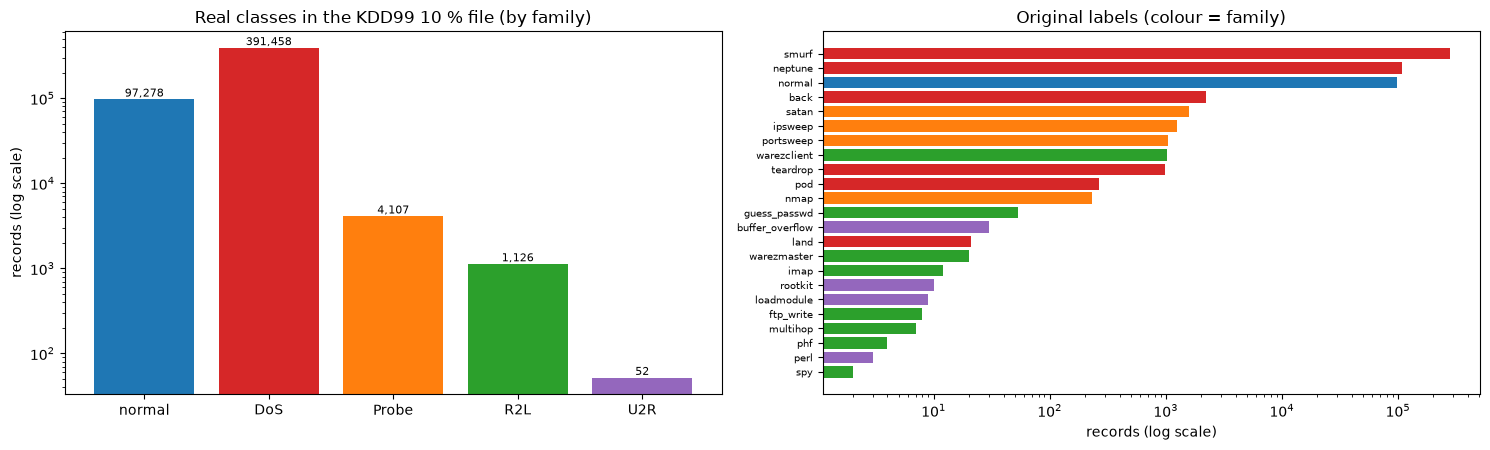

exact duplicate records (all 41 features + label): 70.5%; duplicates on the five used features + label: 85.5%


In [6]:
print("Full KDD99 10 % file:", raw.shape[0], "records,", len(ALL_FEATURES), "features + label")
print("All 41 feature names:\n ", ", ".join(ALL_FEATURES))
print("\nFeatures used by the paper (Table 2):", FEATURES)
lab = raw.groupby(["label", "family"]).size().rename("records").reset_index().sort_values("records", ascending=False)
print(f"\nOriginal label values ({lab.shape[0]} distinct):")
display(lab.set_index("label").T)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
fam_counts = raw.family.value_counts().reindex(FAMILY_ORDER)
axes[0].bar(fam_counts.index, fam_counts.values, color=[FAMILY_COLOR[f] for f in fam_counts.index])
axes[0].set_yscale("log"); axes[0].set_ylabel("records (log scale)"); axes[0].set_title("Real classes in the KDD99 10 % file (by family)")
for i, v in enumerate(fam_counts.values): axes[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
lab_plot = lab.iloc[::-1]
axes[1].barh(lab_plot.label, lab_plot.records, color=[FAMILY_COLOR[f] for f in lab_plot.family])
axes[1].set_xscale("log"); axes[1].set_xlabel("records (log scale)"); axes[1].set_title("Original labels (colour = family)")
axes[1].tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.show()

dup_share = 1 - len(raw.drop_duplicates(subset=ALL_FEATURES + ["label"])) / len(raw)
dup5 = 1 - len(POOLS[True]) / len(raw)
print(f"exact duplicate records (all 41 features + label): {dup_share:.1%}; duplicates on the five used features + label: {dup5:.1%}")

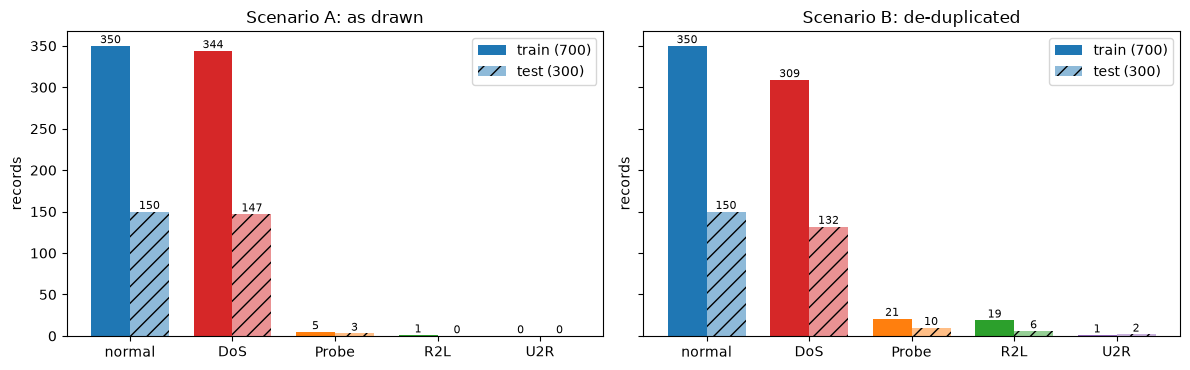

Subset shape (scenario A): train (700, 5) | test (300, 5) | feature columns: ['protocol_type', 'service', 'src_bytes', 'dst_bytes', 'count']
Attack labels in the scenario-A training split: {'smurf': 242, 'neptune': 99, 'back': 3, 'ipsweep': 3, 'warezclient': 1, 'portsweep': 1, 'satan': 1}
Attack labels in the scenario-B training split: {'neptune': 273, 'smurf': 20, 'warezclient': 16, 'satan': 13, 'teardrop': 12, 'portsweep': 7, 'back': 4, 'ftp_write': 2} ...


,protocol_type,service,src_bytes,dst_bytes,count,label
0,0.5,0.429,0.515,0.487,0.024,normal
1,0.0,0.143,0.630,0.000,1.000,smurf
2,0.0,0.143,0.630,0.000,1.000,smurf
3,1.0,0.714,0.423,0.434,0.000,normal
4,0.5,0.429,0.517,0.518,0.047,normal


In [7]:
# the balanced subsets that the models actually see (seed = SEED), by ground-truth family
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, dedup in zip(axes, (False, True)):
    s = get_split(SEED, dedup)
    width = 0.38
    ctr = s["tr"].family.value_counts().reindex(FAMILY_ORDER).fillna(0).astype(int)
    cte = s["te"].family.value_counts().reindex(FAMILY_ORDER).fillna(0).astype(int)
    xs = np.arange(len(FAMILY_ORDER))
    ax.bar(xs - width / 2, ctr.values, width, label="train (700)", color=[FAMILY_COLOR[f] for f in FAMILY_ORDER])
    ax.bar(xs + width / 2, cte.values, width, label="test (300)", color=[FAMILY_COLOR[f] for f in FAMILY_ORDER], alpha=0.5, hatch="//")
    ax.set_xticks(xs); ax.set_xticklabels(FAMILY_ORDER)
    ax.set_title("Scenario " + ("B: de-duplicated" if dedup else "A: as drawn")); ax.set_ylabel("records")
    ax.legend()
    for i, (a, b) in enumerate(zip(ctr.values, cte.values)):
        ax.text(i - width / 2, a, str(a), ha="center", va="bottom", fontsize=8); ax.text(i + width / 2, b, str(b), ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()
s = get_split(SEED, False)
print("Subset shape (scenario A): train", s["Xtr"].shape, "| test", s["Xte"].shape, "| feature columns:", FEATURES)
print("Attack labels in the scenario-A training split:", s["tr"][s["tr"].is_attack == 1].label.value_counts().to_dict())
print("Attack labels in the scenario-B training split:", get_split(SEED, True)["tr"].query("is_attack == 1").label.value_counts().head(8).to_dict(), "...")
display(pd.DataFrame(s["Xtr"][:5], columns=FEATURES).assign(label=s["tr"].label[:5].values).round(3))

**Two-dimensional view of the real records.** The model sees five numbers per connection. To look at them we project the
*training* records with a PCA fitted on the training split (test records are transformed with the same PCA), then show the
same coordinates rescaled to [0, pi] with a min-max scaler fitted on the training split (the convention of the other
notebooks in this repository; the paper itself encodes `-2 pi x`, third panel). Every point is one real connection
coloured by its ground-truth family.

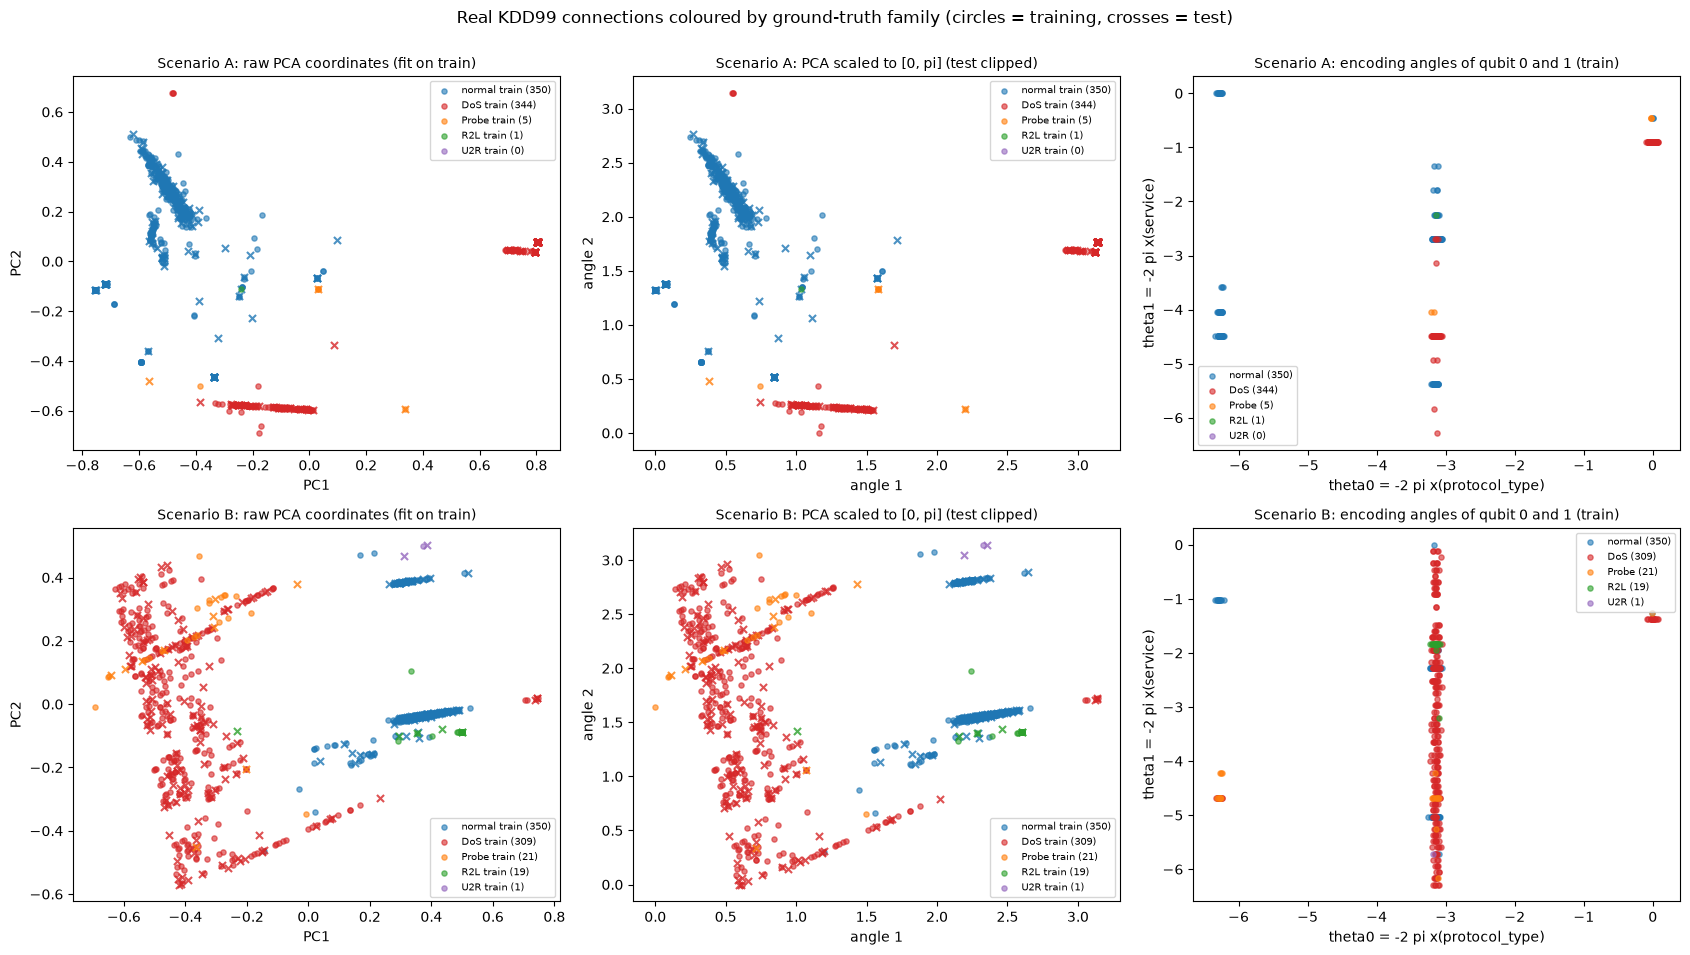

explained variance of the two PCA axes (scenario A, train): [0.711 0.183]


In [8]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9.5))
for r, dedup in enumerate((False, True)):
    s = get_split(SEED, dedup)
    pca = PCA(n_components=2, random_state=SEED).fit(s["Xtr"])                    # fitted on the training split only
    Ptr, Pte = pca.transform(s["Xtr"]), pca.transform(s["Xte"])
    sc_pi = MinMaxScaler((0, np.pi)).fit(Ptr)
    Atr, Ate = sc_pi.transform(Ptr), np.clip(sc_pi.transform(Pte), 0, np.pi)
    ang = -2 * np.pi * s["Xtr"]                                                    # the angles the paper's circuit actually applies
    for ax, (A, B, title, xl, yl) in zip(axes[r], [
            (Ptr, Pte, "raw PCA coordinates (fit on train)", "PC1", "PC2"),
            (Atr, Ate, "PCA scaled to [0, pi] (test clipped)", "angle 1", "angle 2"),
            (None, None, "encoding angles of qubit 0 and 1 (train)", "theta0 = -2 pi x(protocol_type)", "theta1 = -2 pi x(service)")]):
        for fam in FAMILY_ORDER:
            mtr = (s["tr"].family == fam).to_numpy()
            if A is None:
                ax.scatter(ang[mtr, 0] + 0.03 * rng.standard_normal(mtr.sum()), ang[mtr, 1], s=14, alpha=0.6, c=FAMILY_COLOR[fam], label=f"{fam} ({mtr.sum()})")
            else:
                ax.scatter(A[mtr, 0], A[mtr, 1], s=14, alpha=0.6, c=FAMILY_COLOR[fam], label=f"{fam} train ({mtr.sum()})")
                mte = (s["te"].family == fam).to_numpy()
                if mte.sum(): ax.scatter(B[mte, 0], B[mte, 1], s=26, marker="x", c=FAMILY_COLOR[fam], alpha=0.8)
        ax.set_title(("Scenario B: " if dedup else "Scenario A: ") + title, fontsize=10); ax.set_xlabel(xl); ax.set_ylabel(yl); ax.legend(fontsize=7)
plt.suptitle("Real KDD99 connections coloured by ground-truth family (circles = training, crosses = test)", y=1.0)
plt.tight_layout(); plt.show()
print("explained variance of the two PCA axes (scenario A, train):", PCA(2, random_state=SEED).fit(get_split(SEED, False)["Xtr"]).explained_variance_ratio_.round(3))

## 3. Classical baselines on the same five features

The paper compares with an artificial neural network (ANN), SVM, KNN, naive Bayes (NB) and a decision tree (DT) but gives
no settings. We use plain scikit-learn defaults (`# CHOICE`): `MLPClassifier(16, 8)`, `SVC(rbf)`, `KNN(k=5)`,
`GaussianNB`, `DecisionTree`, plus a RandomForest. They receive exactly the normalised features the circuit encodes.

Metrics follow the paper with *attack = positive*: precision, recall, F1, FPR = FP/(FP+TN), FNR = FN/(TP+FN),
FAR = (FPR+FNR)/2, and the mean squared error of the model output against the 0/1 label on the training and the test split.

In [9]:
def metrics_dict(y, pred, score=None):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    fpr = fp / max(fp + tn, 1); fnr = fn / max(tp + fn, 1)
    out = dict(accuracy=100 * accuracy_score(y, pred), precision=100 * precision_score(y, pred, zero_division=0),
               recall=100 * recall_score(y, pred, zero_division=0), f1=100 * f1_score(y, pred, zero_division=0),
               fpr=100 * fpr, fnr=100 * fnr, far=100 * (fpr + fnr) / 2, tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))
    return out

def classical_models(seed):
    return {"ANN": MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=1000, random_state=seed),
            "SVM": SVC(kernel="rbf", probability=True, random_state=seed),
            "KNN": KNeighborsClassifier(n_neighbors=5),
            "NB": GaussianNB(),
            "DT": DecisionTreeClassifier(random_state=seed),
            "RF": RandomForestClassifier(n_estimators=100, random_state=seed)}

def run_classical(split):
    rows = []
    for name, model in classical_models(split["seed"]).items():
        t0 = time.time(); model.fit(split["Xtr"], split["ytr"]); pred = model.predict(split["Xte"]); dt = time.time() - t0
        ptr, pte = model.predict_proba(split["Xtr"])[:, 1], model.predict_proba(split["Xte"])[:, 1]
        m = metrics_dict(split["yte"], pred)
        m.update(model=name, train_mse=mean_squared_error(split["ytr"], ptr), test_mse=mean_squared_error(split["yte"], pte),
                 seconds=dt, seed=split["seed"], scenario="B" if split["dedup"] else "A")
        rows.append(m)
    return rows

CLASSICAL = []
for dedup in (False, True):
    for k in range(N_SEEDS):
        CLASSICAL += run_classical(get_split(SEED + k, dedup))
cl = pd.DataFrame(CLASSICAL)
show = ["accuracy", "precision", "recall", "f1", "fpr", "fnr", "far", "train_mse", "test_mse"]
for scen in ("A", "B"):
    tab = cl[cl.scenario == scen].groupby("model", sort=False)[show].agg(["mean", "std"]).round(2)
    print(f"\nScenario {scen} ({'as drawn' if scen == 'A' else 'de-duplicated'}), mean and std over {N_SEEDS} seeds:")
    display(tab)


Scenario A (as drawn), mean and std over 5 seeds:


accuracy       precision       recall           f1         fpr         fnr         far       train_mse       test_mse      
          mean   std      mean   std   mean   std   mean   std  mean   std  mean   std  mean   std      mean   std     mean   std
model                                                                                                                            
ANN      99.00  0.41     99.60  0.37  98.40  0.60  98.99  0.41  0.40  0.37  1.60  0.60  1.00  0.41      0.01  0.00     0.01  0.00
SVM      98.80  0.69     99.86  0.30  97.73  1.38  98.78  0.71  0.13  0.30  2.27  1.38  1.20  0.69      0.01  0.00     0.01  0.01
KNN      99.00  0.82     99.73  0.37  98.27  1.53  98.99  0.83  0.27  0.37  1.73  1.53  1.00  0.82      0.00  0.00     0.01  0.01
NB       96.53  2.17     94.81  4.26  98.67  0.82  96.65  1.98  5.60  4.98  1.33  0.82  3.47  2.17      0.02  0.01     0.03  0.01
DT       99.13  0.56     99.33  0.66  98.93  0.76  99.13  0.56  0.67  0.67  1.07  0.76  0.87  0.56      0.00  0.00     0.01  0.01
RF       99.20  0.51     99.47  0.73  98.93  0.76  99.20  0.51  0.53  0.73  1.07  0.76  0.80  0.51      0.00  0.00     0.01  0.00


Scenario B (de-duplicated), mean and std over 5 seeds:


accuracy       precision       recall           f1         fpr         fnr         far       train_mse       test_mse      
          mean   std      mean   std   mean   std   mean   std  mean   std  mean   std  mean   std      mean   std     mean   std
model                                                                                                                            
ANN      96.60  2.50     98.24  0.84  94.93  5.59  96.48  2.69  1.73  0.89  5.07  5.59  3.40  2.50      0.02  0.02     0.03  0.02
SVM      97.73  1.66     99.04  0.60  96.40  3.32  97.68  1.75  0.93  0.60  3.60  3.32  2.27  1.66      0.01  0.00     0.01  0.01
KNN      98.40  0.83     98.81  1.26  98.00  1.41  98.39  0.83  1.20  1.28  2.00  1.41  1.60  0.83      0.01  0.00     0.01  0.01
NB       93.93  1.69     93.31  1.35  94.67  2.91  93.96  1.74  6.80  1.45  5.33  2.91  6.07  1.69      0.05  0.01     0.06  0.02
DT       97.87  0.90     97.74  0.74  98.00  1.70  97.86  0.92  2.27  0.76  2.00  1.70  2.13  0.90      0.00  0.00     0.02  0.01
RF       98.40  0.55     98.02  0.78  98.80  1.10  98.41  0.55  2.00  0.82  1.20  1.10  1.60  0.55      0.00  0.00     0.01  0.00

## Quantum Circuit Architecture

The circuit below is the object that is **trained and evaluated** in this notebook (a PennyLane QNode on `default.qubit`).
It follows Figs. 7 and 8 of the paper:

1. **Encoding (Fig. 7).** `H` on each of the 5 qubits, then `Rz(theta_i)` with `theta_i = -2 pi x_i` (the 5 normalised
   features in [0, 1]).
2. **Variational layer (Fig. 8).** On every qubit `Rz(gamma)` then `Ry(beta)` then `Rz(alpha)`, i.e. the operator
   `R = Rz(alpha) Ry(beta) Rz(gamma)` of eq. (9) (rightmost factor acts first), followed by CNOT gates. The figure's
   wiring is not recoverable from the paper text; **assumption:** a CNOT chain `0->1, 1->2, 2->3, 3->4` after every
   rotation layer. The layer is repeated `N = 8` times with independent angles.
3. **Measurement.** The paper measures in the Z basis and maps the bit string with `g(a)`; **assumption:** only the last
   qubit is read out, `P(attack) = (1 - <Z_4>)/2`. The last qubit is the one that receives information from all others
   through the CNOT chain.
4. **Inputs the paper omits:** initial angles uniform in [0, 2 pi), loss = mean squared error, mini-batch 32.

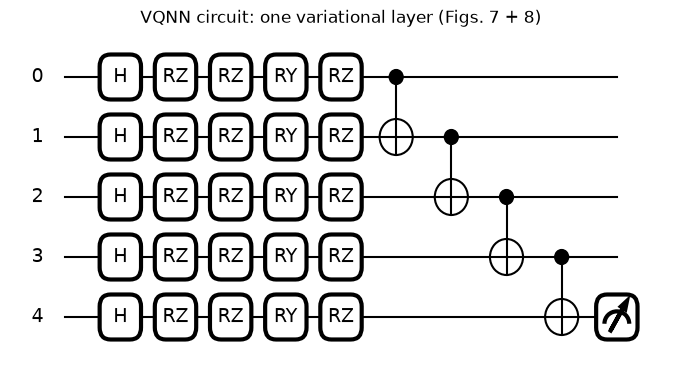

depth N=1: qubits = 5 | circuit depth = 9 | gates = 29 | trainable parameters = 15 (= 1 layers x 5 qubits x 3 angles) | CNOTs = 4


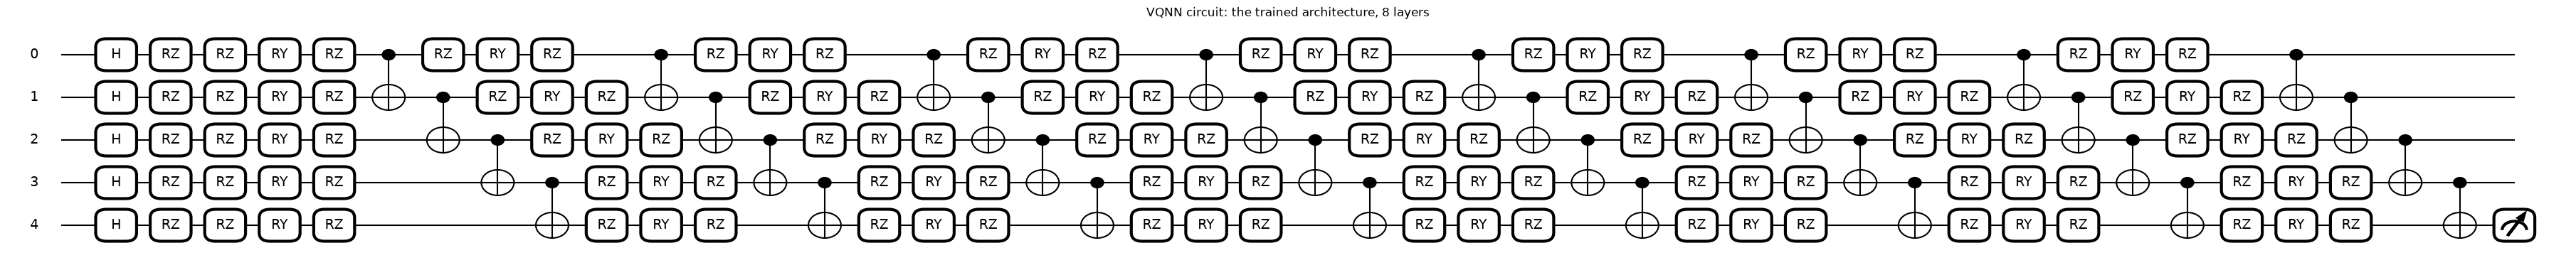

depth N=8: qubits = 5 | circuit depth = 44 | gates = 162 | trainable parameters = 120 (= 8 layers x 5 qubits x 3 angles) | CNOTs = 32


In [10]:
dev = qml.device("default.qubit", wires=N_QUBITS)

def encoding(x):
    # Fig. 7: Hadamard, then Rz(theta_i) with theta_i = -2*pi*x_i. x has shape (N_QUBITS,) or (batch, N_QUBITS)
    for i in range(N_QUBITS):
        qml.Hadamard(wires=i)
        qml.RZ(-2 * np.pi * (x[..., i]), wires=i)

def variational_layer(w_layer):
    # Fig. 8 / eq. (9): R(alpha, beta, gamma) = Rz(alpha) Ry(beta) Rz(gamma) on every qubit (gamma acts first), then CNOTs
    for i in range(N_QUBITS):
        qml.RZ(w_layer[i, 2], wires=i)      # gamma
        qml.RY(w_layer[i, 1], wires=i)      # beta
        qml.RZ(w_layer[i, 0], wires=i)      # alpha
    for i in range(N_QUBITS - 1):           # CHOICE: CNOT chain 0->1->2->3->4
        qml.CNOT(wires=[i, i + 1])

@qml.qnode(dev, interface="autograd", diff_method="backprop")
def vqnn(x, w):
    encoding(x)
    for l in range(w.shape[0]):
        variational_layer(w[l])
    return qml.expval(qml.PauliZ(N_QUBITS - 1))     # CHOICE: read-out qubit = the last one

def p_attack(X, w):
    return (1 - vqnn(X, w)) / 2

x_demo = pnp.array(get_split(SEED, False)["Xtr"][0], requires_grad=False)
for depth, tag in [(1, "one variational layer (Figs. 7 + 8)"), (DEPTH, f"the trained architecture, {DEPTH} layers")]:
    w_demo = pnp.array(np.random.default_rng(SEED).uniform(0, 2 * np.pi, (depth, N_QUBITS, 3)), requires_grad=True)
    fig, ax = qml.draw_mpl(vqnn, decimals=None, style="black_white")(x_demo, w_demo)
    fig.set_size_inches(min(2.0 + 1.1 * depth * 4.2, 36), 3.6); fig.suptitle(f"VQNN circuit: {tag}", y=1.02)
    plt.show()
    specs = qml.specs(vqnn)(x_demo, w_demo)
    print(f"depth N={depth}: qubits = {N_QUBITS} | circuit depth = {specs['resources'].depth} | gates = {specs['resources'].num_gates} "
          f"| trainable parameters = {w_demo.size} (= {depth} layers x {N_QUBITS} qubits x 3 angles) | CNOTs = {depth * (N_QUBITS - 1)}")

## 4. Training the VQNN

Adam with learning rate 0.01 on the mean squared error between `P(attack)` and the label, 10 passes over the 700
training records in mini-batches of 32. The cost and its gradients come from exact back-propagation through the
state-vector simulation (the paper's TFQ also differentiates a simulated circuit). After every epoch we record the
training MSE and the test accuracy so that the learning curve can be drawn; the test numbers are **never** used to
choose anything.

epoch  1 | train MSE 0.0839 | test MSE 0.0839 | test acc 93.33 % | 7 s


epoch  2 | train MSE 0.0556 | test MSE 0.0575 | test acc 97.00 % | 14 s


epoch  3 | train MSE 0.0433 | test MSE 0.0470 | test acc 97.00 % | 21 s


epoch  4 | train MSE 0.0366 | test MSE 0.0400 | test acc 97.00 % | 28 s


epoch  5 | train MSE 0.0319 | test MSE 0.0354 | test acc 97.00 % | 36 s


epoch  6 | train MSE 0.0276 | test MSE 0.0311 | test acc 97.33 % | 45 s


epoch  7 | train MSE 0.0248 | test MSE 0.0279 | test acc 97.00 % | 53 s


epoch  8 | train MSE 0.0232 | test MSE 0.0263 | test acc 97.33 % | 62 s


epoch  9 | train MSE 0.0223 | test MSE 0.0252 | test acc 97.33 % | 71 s


epoch 10 | train MSE 0.0216 | test MSE 0.0246 | test acc 97.33 % | 79 s

VQNN depth 8, scenario A, seed 42: accuracy 97.33 % | precision 95.51 % | recall 99.33 % | F1 97.39 % | train MSE 0.0216 | test MSE 0.0246 | 79 s


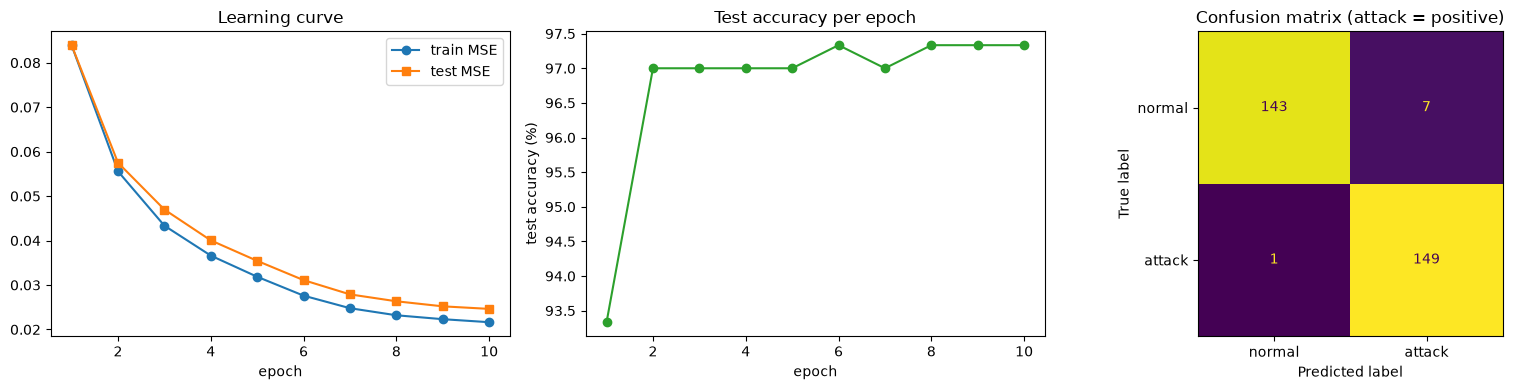

In [11]:
RUNS = {}      # (scenario, depth, seed) -> result dict

def train_vqnn(split, depth=DEPTH, epochs=EPOCHS, lr=LEARNING_RATE, batch=BATCH_SIZE, seed=None, verbose=False):
    seed = split["seed"] if seed is None else seed
    key = ("B" if split["dedup"] else "A", depth, seed)
    if key in RUNS and RUNS[key]["epochs"] == epochs:
        return RUNS[key]
    rng_i = np.random.default_rng(seed)
    w = pnp.array(rng_i.uniform(0, 2 * np.pi, (depth, N_QUBITS, 3)), requires_grad=True)   # CHOICE: uniform [0, 2 pi)
    opt = qml.AdamOptimizer(stepsize=lr)
    Xtr, ytr, Xte, yte = split["Xtr"], split["ytr"].astype(float), split["Xte"], split["yte"]
    def cost(w_, xb, yb):
        return pnp.mean((p_attack(xb, w_) - yb) ** 2)
    hist = []; t0 = time.time()
    for ep in range(epochs):
        perm = rng_i.permutation(len(ytr))
        for k in range(0, len(perm), batch):
            idx = perm[k:k + batch]
            xb = pnp.array(Xtr[idx], requires_grad=False); yb = pnp.array(ytr[idx], requires_grad=False)
            w = opt.step(lambda w_: cost(w_, xb, yb), w)
        ptr, pte = np.asarray(p_attack(Xtr, w)), np.asarray(p_attack(Xte, w))
        hist.append(dict(epoch=ep + 1, train_mse=float(np.mean((ptr - ytr) ** 2)), test_mse=float(np.mean((pte - yte) ** 2)),
                         test_acc=100 * float(np.mean((pte > 0.5) == yte)), seconds=time.time() - t0))
        if verbose:
            print(f"epoch {ep + 1:2d} | train MSE {hist[-1]['train_mse']:.4f} | test MSE {hist[-1]['test_mse']:.4f} | test acc {hist[-1]['test_acc']:.2f} % | {hist[-1]['seconds']:.0f} s")
    pred = (pte > 0.5).astype(int)
    m = metrics_dict(split["yte"], pred)
    m.update(depth=depth, seed=seed, scenario=key[0], epochs=epochs, train_mse=hist[-1]["train_mse"], test_mse=hist[-1]["test_mse"],
             seconds=time.time() - t0, weights=np.asarray(w), history=pd.DataFrame(hist), p_test=pte, pred=pred)
    RUNS[key] = m
    return m

res0 = train_vqnn(get_split(SEED, False), verbose=True)
print(f"\nVQNN depth {DEPTH}, scenario A, seed {SEED}: accuracy {res0['accuracy']:.2f} % | precision {res0['precision']:.2f} % | "
      f"recall {res0['recall']:.2f} % | F1 {res0['f1']:.2f} % | train MSE {res0['train_mse']:.4f} | test MSE {res0['test_mse']:.4f} | {res0['seconds']:.0f} s")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
h = res0["history"]
axes[0].plot(h.epoch, h.train_mse, "o-", label="train MSE"); axes[0].plot(h.epoch, h.test_mse, "s-", label="test MSE")
axes[0].set_xlabel("epoch"); axes[0].set_title("Learning curve"); axes[0].legend()
axes[1].plot(h.epoch, h.test_acc, "o-", color="tab:green"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("test accuracy (%)"); axes[1].set_title("Test accuracy per epoch")
ConfusionMatrixDisplay(confusion_matrix(get_split(SEED, False)["yte"], res0["pred"]), display_labels=["normal", "attack"]).plot(ax=axes[2], colorbar=False)
axes[2].set_title("Confusion matrix (attack = positive)")
plt.tight_layout(); plt.show()

### Headline runs over several seeds

Each seed gives a new balanced draw, a new train/test split and a new random initialisation. Scenario A is the paper's
setting as far as it can be read; scenario B removes duplicate records first.

VQNN depth 8 (577 s for the runs not trained above)


accuracy       precision       recall           f1         fpr         fnr         far       train_mse      test_mse       seconds       
             mean   std      mean   std   mean   std   mean   std  mean   std  mean   std  mean   std      mean  std     mean   std    mean    std
scenario                                                                                                                                          
A           98.00  1.13     97.01  1.67  99.07  0.76  98.03  1.11  3.07  1.74  0.93  0.76  2.00  1.13      0.02  0.0     0.03  0.00   92.53  17.56
B           96.33  1.76     97.72  1.40  94.89  3.15  96.27  1.85  2.22  1.39  5.11  3.15  3.67  1.76      0.03  0.0     0.04  0.01   64.17   3.85

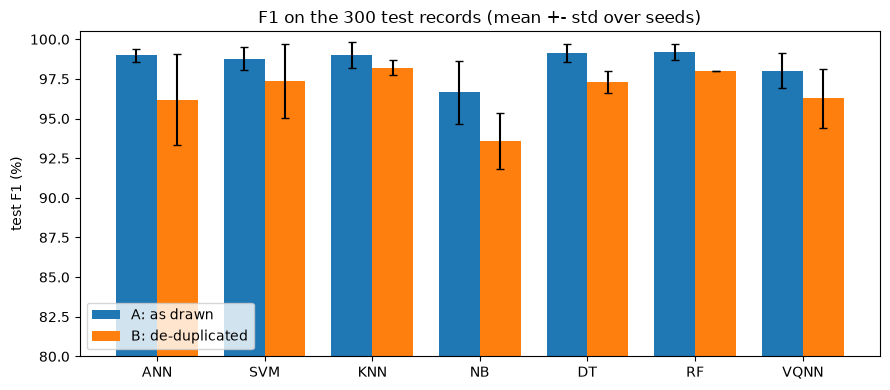

Test records that have an identical twin in the training set (scenario A mean): 49.9% | scenario B: 0.0%


In [12]:
t0 = time.time()
for k in range(N_SEEDS):
    train_vqnn(get_split(SEED + k, False))
for k in range(DEDUP_SEEDS):
    train_vqnn(get_split(SEED + k, True))
vq = pd.DataFrame([{k: v for k, v in r.items() if k not in ("weights", "history", "p_test", "pred")} for key, r in RUNS.items() if key[1] == DEPTH])
show_v = ["accuracy", "precision", "recall", "f1", "fpr", "fnr", "far", "train_mse", "test_mse", "seconds"]
print(f"VQNN depth {DEPTH} ({time.time() - t0:.0f} s for the runs not trained above)")
display(vq.groupby("scenario")[show_v].agg(["mean", "std"]).round(2))

# classical vs VQNN, F1 on the test split, mean +- std
rows = []
for scen, n in (("A", N_SEEDS), ("B", DEDUP_SEEDS)):
    for name in ["ANN", "SVM", "KNN", "NB", "DT", "RF"]:
        v = cl[(cl.scenario == scen) & (cl.model == name) & (cl.seed < SEED + n)].f1
        rows.append(dict(scenario=scen, model=name, f1_mean=v.mean(), f1_std=v.std()))
    v = vq[vq.scenario == scen].f1
    rows.append(dict(scenario=scen, model="VQNN", f1_mean=v.mean(), f1_std=v.std()))
cmp_f1 = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 4))
order = ["ANN", "SVM", "KNN", "NB", "DT", "RF", "VQNN"]
for j, scen in enumerate(("A", "B")):
    d = cmp_f1[cmp_f1.scenario == scen].set_index("model").loc[order]
    ax.bar(np.arange(len(order)) + (j - 0.5) * 0.38, d.f1_mean, 0.38, yerr=d.f1_std.fillna(0), capsize=3,
           label="A: as drawn" if scen == "A" else "B: de-duplicated")
ax.set_xticks(range(len(order))); ax.set_xticklabels(order); ax.set_ylabel("test F1 (%)"); ax.set_ylim(80, 100.5); ax.legend(); ax.set_title("F1 on the 300 test records (mean +- std over seeds)")
plt.tight_layout(); plt.show()
print("Test records that have an identical twin in the training set (scenario A mean):", f"{np.mean([get_split(SEED + k, False)['twin_share'] for k in range(N_SEEDS)]):.1%}",
      "| scenario B:", f"{np.mean([get_split(SEED + k, True)['twin_share'] for k in range(DEDUP_SEEDS)]):.1%}")

## 5. Circuit depth sweep (Table 3)

The paper trains the circuit with `N = 1 ... 10` layers and finds the best test result at `N = 8`, with a drop afterwards.
The same sweep is run here on scenario A (10 epochs each). Wall-clock times are not comparable with the paper's
(different simulator, hardware and batch size) and are shown only to illustrate the growth with depth.

depth sweep done in 1260 s (seeds: 2)


,accuracy,precision,recall,f1,train_mse,test_mse,seconds
depth,,,,,,,
1,82.000,75.464,95.000,84.092,0.129,0.132,7.434
2,87.167,83.024,93.667,87.993,0.099,0.097,16.820
3,96.167,94.289,98.333,96.262,0.045,0.041,22.700
4,98.167,97.383,99.000,98.183,0.039,0.040,55.411
5,98.000,97.071,99.000,98.022,0.031,0.030,45.529
6,98.000,98.000,98.000,97.995,0.024,0.023,77.737
7,97.833,97.065,98.667,97.852,0.026,0.027,101.836
8,97.833,96.763,99.000,97.862,0.026,0.025,86.725
9,98.000,97.071,99.000,98.022,0.023,0.022,121.794


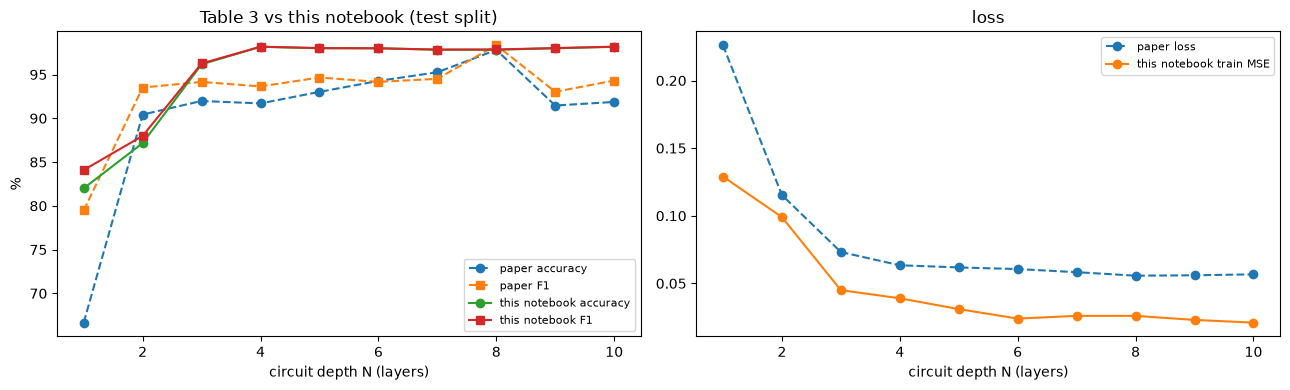

In [13]:
t0 = time.time()
for depth in sorted(set(SWEEP_DEPTHS) | {DEPTH}):
    for k in range(SWEEP_SEEDS):
        train_vqnn(get_split(SEED + k, False), depth=depth)
sw = pd.DataFrame([{k: v for k, v in r.items() if k not in ("weights", "history", "p_test", "pred")}
                   for key, r in RUNS.items() if key[0] == "A" and key[2] < SEED + SWEEP_SEEDS])
sweep = sw.groupby("depth")[["accuracy", "precision", "recall", "f1", "train_mse", "test_mse", "seconds"]].mean().round(3)
print(f"depth sweep done in {time.time() - t0:.0f} s (seeds: {SWEEP_SEEDS})")
display(sweep)

PAPER_T3 = pd.DataFrame({
    "depth": range(1, 11),
    "time_s": [13, 31, 67, 116, 184, 271, 413, 661, 841, 1184],
    "accuracy": [66.66, 90.43, 91.98, 91.70, 93.02, 94.27, 95.26, 97.81, 91.46, 91.87],
    "precision": [66.36, 91.88, 93.72, 92.47, 94.09, 95.53, 95.74, 97.21, 95.32, 91.56],
    "recall": [100.00, 93.28, 94.90, 95.13, 95.39, 96.28, 96.13, 99.55, 91.55, 97.72],
    "f1": [79.47, 93.51, 94.16, 93.64, 94.66, 94.16, 94.51, 98.35, 93.03, 94.31],
    "loss": [0.2261, 0.1153, 0.0732, 0.0634, 0.0618, 0.0606, 0.0583, 0.0557, 0.0560, 0.0567]}).set_index("depth")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(PAPER_T3.index, PAPER_T3.accuracy, "o--", label="paper accuracy"); axes[0].plot(PAPER_T3.index, PAPER_T3.f1, "s--", label="paper F1")
axes[0].plot(sweep.index, sweep.accuracy, "o-", label="this notebook accuracy"); axes[0].plot(sweep.index, sweep.f1, "s-", label="this notebook F1")
axes[0].set_xlabel("circuit depth N (layers)"); axes[0].set_ylabel("%"); axes[0].set_title("Table 3 vs this notebook (test split)"); axes[0].legend(fontsize=8)
axes[1].plot(PAPER_T3.index, PAPER_T3.loss, "o--", label="paper loss"); axes[1].plot(sweep.index, sweep.train_mse, "o-", label="this notebook train MSE")
axes[1].set_xlabel("circuit depth N (layers)"); axes[1].set_title("loss"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6. The "real IBM quantum machine" experiment (Table 7), emulated

The paper copies the trained angles into a circuit on IBMQ, sends **100 randomly chosen test records** to the six free
5-qubit devices (`ibmq_manila, bogota, santiago, quito, belem, lima`), repeats each record 1000 times and calls a record an
attack when `1` is the more frequent outcome (Fig. 12). Nothing can be sent to real hardware from here, so the same
procedure runs on the **calibrated noise models of the six fake devices** shipped with `qiskit-ibm-runtime`
(`FakeManilaV2`, ...). The noise models are snapshots of these machines' calibration data, so this is an emulation, not a
re-measurement: the actual 2022 hardware noise is not available.

First the trained PennyLane circuit is rebuilt in Qiskit from the same gate list and **checked for equivalence**
with an exact state-vector evaluation.

PennyLane and Qiskit give the same P(attack) for 8 test records (max difference 7.2e-16): equivalence verified.


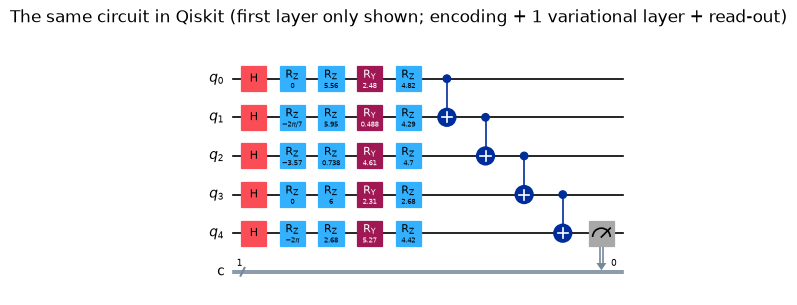

Qiskit circuit (logical, before transpilation): qubits 5 | depth 45 | gate counts {'rz': 85, 'ry': 40, 'cx': 32, 'h': 5, 'measure': 1}


In [14]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
import qiskit_ibm_runtime.fake_provider as fake_provider

def qiskit_vqnn(x, w, measure=True):
    # the same gate list as the PennyLane QNode: H, Rz(-2 pi x_i); per layer Rz(gamma) Ry(beta) Rz(alpha) on each qubit, CNOT chain
    qc = QuantumCircuit(N_QUBITS, 1 if measure else 0)
    for i in range(N_QUBITS):
        qc.h(i); qc.rz(float(-2 * np.pi * x[i]), i)
    for l in range(w.shape[0]):
        for i in range(N_QUBITS):
            qc.rz(float(w[l, i, 2]), i); qc.ry(float(w[l, i, 1]), i); qc.rz(float(w[l, i, 0]), i)
        for i in range(N_QUBITS - 1):
            qc.cx(i, i + 1)
    if measure:
        qc.measure(N_QUBITS - 1, 0)
    return qc

run_A = RUNS[("A", DEPTH, SEED)]
W = run_A["weights"]; split_A = get_split(SEED, False)
# equivalence check: PennyLane P(attack) == Qiskit exact probability of reading 1 on the last qubit
chk = []
for j in range(8):
    p_ql = Statevector(qiskit_vqnn(split_A["Xte"][j], W, measure=False)).probabilities([N_QUBITS - 1])[1]
    chk.append((float(p_attack(split_A["Xte"][j], pnp.array(W))), p_ql))
chk = np.array(chk)
assert np.allclose(chk[:, 0], chk[:, 1], atol=1e-8), "PennyLane and Qiskit circuits differ"
print("PennyLane and Qiskit give the same P(attack) for 8 test records (max difference %.1e): equivalence verified." % np.abs(chk[:, 0] - chk[:, 1]).max())
fig = qiskit_vqnn(split_A["Xte"][0], W[:1]).draw("mpl", fold=-1, scale=0.6)
fig.suptitle("The same circuit in Qiskit (first layer only shown; encoding + 1 variational layer + read-out)", y=1.0)
display(fig); plt.close(fig)
qc_full = qiskit_vqnn(split_A["Xte"][0], W)
print("Qiskit circuit (logical, before transpilation): qubits", qc_full.num_qubits, "| depth", qc_full.depth(), "| gate counts", dict(qc_full.count_ops()))

FakeManilaV2: 17 records, transpiled depth ~59, two-qubit gates ~32


FakeBogotaV2: 17 records, transpiled depth ~59, two-qubit gates ~32


FakeSantiagoV2: 17 records, transpiled depth ~59, two-qubit gates ~32


FakeQuitoV2: 17 records, transpiled depth ~107, two-qubit gates ~53


FakeBelemV2: 16 records, transpiled depth ~107, two-qubit gates ~53


FakeLimaV2: 16 records, transpiled depth ~107, two-qubit gates ~53
noisy emulation done in 12 s


mean |P(attack) - 0.5|: ideal 0.405 vs noisy 0.181 (noise pulls the outcome frequencies towards 0.5)

Fig. 12 analogue: one attack record on FakeManilaV2 -> counts {'0': 232, '1': 768} (paper: 516 x '1', 484 x '0')


,accuracy,precision,recall,f1,fpr,fnr,far,tp,fp,fn,tn
ideal simulator (same records),97.0,93.88,100.0,96.84,5.56,0.0,2.78,46,3,0,51
noisy device emulation,97.0,93.88,100.0,96.84,5.56,0.0,2.78,46,3,0,51


,records,accuracy_noisy,accuracy_ideal
device,,,
FakeManilaV2,17.0,100.0,100.0
FakeBogotaV2,17.0,94.1,94.1
FakeSantiagoV2,17.0,100.0,100.0
FakeQuitoV2,17.0,94.1,94.1
FakeBelemV2,16.0,100.0,100.0
FakeLimaV2,16.0,93.8,93.8


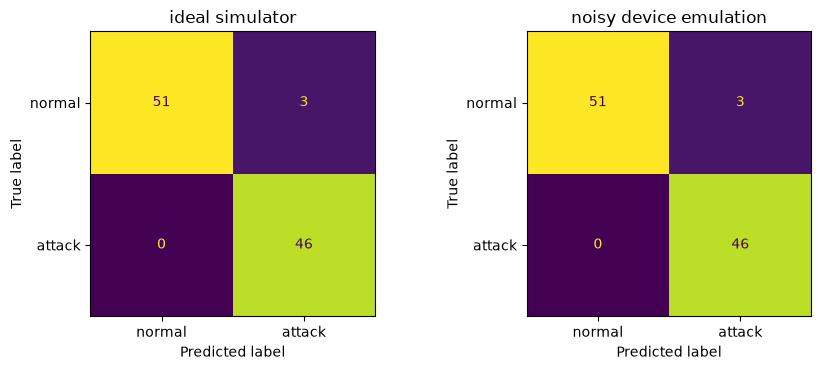

Table 7 recomputed from its own confusion matrix: {'accuracy': 80.0, 'precision': 85.25, 'recall': 82.54, 'fpr': 24.32, 'fnr': 17.46, 'f1': 83.87, 'far': 20.89}
Values the text states: precision 85.25, recall 82.54, F1 83.87, FPR 14.29, FNR 14.75, FAR 14.52 -> FPR/FNR/FAR do not follow from Table 7 (see the critical section).


In [15]:
rs = np.random.default_rng(SEED)
ibm_idx = rs.choice(len(split_A["yte"]), size=N_IBM, replace=False)       # CHOICE: random test records (paper: 100 random records, 63 attacks / 37 normal)
dev_of = np.array_split(ibm_idx, len(IBM_DEVICES))                         # records spread over the six devices, as in the paper
p_noisy = np.zeros(len(ibm_idx)); dev_name = np.empty(len(ibm_idx), dtype=object); counts1 = np.zeros(len(ibm_idx), dtype=int)
t0 = time.time(); pos = 0; first_counts = None
for name, idx in zip(IBM_DEVICES, dev_of):
    backend = getattr(fake_provider, name)()
    sim = AerSimulator.from_backend(backend)
    circs = [qiskit_vqnn(split_A["Xte"][i], W) for i in idx]
    tcircs = transpile(circs, backend, optimization_level=1, seed_transpiler=SEED)
    result = sim.run(tcircs, shots=SHOTS, seed_simulator=SEED).result()
    for j in range(len(idx)):
        c1 = result.get_counts(j).get("1", 0)
        counts1[pos] = c1; p_noisy[pos] = c1 / SHOTS; dev_name[pos] = name; pos += 1
        if first_counts is None and split_A["yte"][idx[j]] == 1:
            first_counts = (name, result.get_counts(j))
    print(f"{name}: {len(idx)} records, transpiled depth ~{int(np.mean([t.depth() for t in tcircs]))}, two-qubit gates ~{int(np.mean([t.count_ops().get('cx', 0) + t.count_ops().get('ecr', 0) + t.count_ops().get('cz', 0) for t in tcircs]))}")
print(f"noisy emulation done in {time.time() - t0:.0f} s")

y_ibm = split_A["yte"][ibm_idx]
pred_noisy = (p_noisy > 0.5).astype(int)
pred_ideal = (np.asarray(p_attack(split_A["Xte"][ibm_idx], pnp.array(W))) > 0.5).astype(int)
m_noisy = metrics_dict(y_ibm, pred_noisy); m_ideal = metrics_dict(y_ibm, pred_ideal)
print(f"mean |P(attack) - 0.5|: ideal {np.abs(np.asarray(p_attack(split_A['Xte'][ibm_idx], pnp.array(W))) - 0.5).mean():.3f} vs noisy {np.abs(p_noisy - 0.5).mean():.3f} (noise pulls the outcome frequencies towards 0.5)")
print("\nFig. 12 analogue: one attack record on", first_counts[0], "-> counts", dict(first_counts[1]), "(paper: 516 x '1', 484 x '0')")
tab = pd.DataFrame([m_ideal, m_noisy], index=["ideal simulator (same records)", "noisy device emulation"])[["accuracy", "precision", "recall", "f1", "fpr", "fnr", "far", "tp", "fp", "fn", "tn"]].round(2)
display(tab)
per_dev = pd.DataFrame({"device": dev_name, "y": y_ibm, "pred": pred_noisy, "ideal": pred_ideal}).groupby("device", sort=False).apply(
    lambda d: pd.Series(dict(records=len(d), accuracy_noisy=100 * (d.y == d.pred).mean(), accuracy_ideal=100 * (d.y == d.ideal).mean())), include_groups=False)
display(per_dev.round(1))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
ConfusionMatrixDisplay(confusion_matrix(y_ibm, pred_ideal, labels=[0, 1]), display_labels=["normal", "attack"]).plot(ax=axes[0], colorbar=False); axes[0].set_title("ideal simulator")
ConfusionMatrixDisplay(confusion_matrix(y_ibm, pred_noisy, labels=[0, 1]), display_labels=["normal", "attack"]).plot(ax=axes[1], colorbar=False); axes[1].set_title("noisy device emulation")
plt.tight_layout(); plt.show()

# the paper's Table 7: TP=52, FP=9, FN=11, TN=28 -> metrics recomputed from the formulae (16) to (21)
tp, fp, fn, tn = 52, 9, 11, 28
paper_t7 = dict(accuracy=100 * (tp + tn) / 100, precision=100 * tp / (tp + fp), recall=100 * tp / (tp + fn),
                fpr=100 * fp / (fp + tn), fnr=100 * fn / (tp + fn))
paper_t7["f1"] = 2 * paper_t7["precision"] * paper_t7["recall"] / (paper_t7["precision"] + paper_t7["recall"]); paper_t7["far"] = (paper_t7["fpr"] + paper_t7["fnr"]) / 2
print("Table 7 recomputed from its own confusion matrix:", {k: round(v, 2) for k, v in paper_t7.items()})
print("Values the text states: precision 85.25, recall 82.54, F1 83.87, FPR 14.29, FNR 14.75, FAR 14.52 -> FPR/FNR/FAR do not follow from Table 7 (see the critical section).")

## 7. Side by side with the paper

Verdict rule: a value is **reproduced** when it is within 2 percentage points (0.02 F1, or 0.02 for the MSE-type losses)
of the paper's value; otherwise **exceeded** (better than the paper by the stated gap) or **not reached**. Claims that
cannot be tested here are marked **cannot be checked**. Measured values use scenario A (the paper's setting as far as it
can be read), mean over the headline seeds; scenario B is shown separately.

In [16]:
def verdict(paper, ours, tol=TOL_PTS, lower_is_better=False):
    d = ours - paper
    if abs(d) <= tol: return "reproduced"
    better = (d < 0) if lower_is_better else (d > 0)
    return f"exceeded by {abs(d):.2f}" if better else f"not reached (gap {abs(d):.2f})"

A = vq[vq.scenario == "A"]; Bv = vq[vq.scenario == "B"]
rows = []
def add(claim, paper, ours, lower=False, tol=TOL_PTS, fmt="{:.2f}"):
    rows.append(dict(claim=claim, paper=fmt.format(paper), notebook=fmt.format(ours), verdict=verdict(paper, ours, tol, lower)))

# Table 3 / 5, depth 8
add("VQNN depth 8: accuracy % (Table 3)", 97.81, A.accuracy.mean())
add("VQNN depth 8: precision % (Tables 3, 5)", 97.21, A.precision.mean())
add("VQNN depth 8: recall % (Tables 3, 5)", 99.55, A.recall.mean())
add("VQNN depth 8: F1 % (Tables 3, 5)", 98.35, A.f1.mean())
add("VQNN training MSE (Table 5)", 0.0479, A.train_mse.mean(), lower=True, tol=0.02, fmt="{:.4f}")
add("VQNN test MSE (Table 5)", 0.0589, A.test_mse.mean(), lower=True, tol=0.02, fmt="{:.4f}")
add("VQNN FPR % (Table 5)", 6.85, A.fpr.mean(), lower=True)
add("VQNN FNR % (Table 5)", 1.36, A.fnr.mean(), lower=True)
add("VQNN FAR % (Table 5)", 4.11, A.far.mean(), lower=True)
# depth trend
if 1 in sweep.index:
    add("depth 1 is weak: accuracy % (Table 3)", 66.66, sweep.loc[1, "accuracy"])
if set([8, 9, 10]) <= set(sweep.index):
    best = sweep.f1.idxmax()
    rows.append(dict(claim="best depth is N = 8 and N = 9, 10 are worse (Table 3)", paper="best N=8",
                     notebook=f"best N={best}; F1 N=8/9/10: " + "/".join(f"{sweep.loc[n, 'f1']:.1f}" for n in (8, 9, 10)),
                     verdict="reproduced" if best == 8 and sweep.loc[9, "f1"] < sweep.loc[8, "f1"] and sweep.loc[10, "f1"] < sweep.loc[8, "f1"] else "not reached"))
else:
    rows.append(dict(claim="best depth is N = 8 and N = 9, 10 are worse (Table 3)", paper="best N=8", notebook="sweep limited to " + str(sorted(sweep.index)), verdict="cannot be checked (FAST_MODE sweep)"))
# Table 5 classical
PAPER_T5 = {"ANN": (90.00, 86.01, 87.37, 12.84, 5.23, 9.04), "SVM": (81.17, 64.68, 64.16, 25.65, 11.32, 18.49),
            "KNN": (87.75, 85.73, 86.53, 16.66, 9.74, 13.20), "NB": (84.76, 83.68, 84.15, 18.87, 10.96, 14.92),
            "DT": (87.64, 83.88, 85.15, 15.26, 8.83, 12.05)}
clA = cl[(cl.scenario == "A") & (cl.seed < SEED + N_SEEDS)].groupby("model")[["precision", "recall", "f1", "fpr", "fnr", "far"]].mean()
for name, (pp, pr, pf, pfpr, pfnr, pfar) in PAPER_T5.items():
    add(f"{name}: precision % (Table 5)", pp, clA.loc[name, "precision"]); add(f"{name}: recall % (Table 5)", pr, clA.loc[name, "recall"])
    add(f"{name}: F1 % (Table 5)", pf, clA.loc[name, "f1"])
# ranking claim
f1_all = {n: clA.loc[n, "f1"] for n in PAPER_T5}; f1_all["VQNN"] = A.f1.mean()
best_model = max(f1_all, key=f1_all.get)
rows.append(dict(claim="VQNN has the highest F1 of all compared models (Table 5)", paper="VQNN best",
                 notebook="best: " + best_model + " (" + ", ".join(f"{k} {v:.1f}" for k, v in f1_all.items()) + ")",
                 verdict="reproduced" if best_model == "VQNN" else "not reached (a classical model is at least as good)"))
# Table 7
add("IBM: precision % (Table 7 / text)", 85.25, m_noisy["precision"]); add("IBM: recall % (Table 7 / text)", 82.54, m_noisy["recall"])
add("IBM: F1 % (Table 7 / text)", 83.87, m_noisy["f1"])
add("IBM: FPR % (text 14.29; Table 7 gives 24.32)", 14.29, m_noisy["fpr"], lower=True); add("IBM: FNR % (text 14.75; Table 7 gives 17.46)", 14.75, m_noisy["fnr"], lower=True)
rows.append(dict(claim="noisy-device VQNN still beats SVM and NB (Section 4.3)", paper="beats SVM (64.16) and NB (84.15) in F1",
                 notebook=f"emulated F1 {m_noisy['f1']:.1f} vs our SVM {clA.loc['SVM', 'f1']:.1f}, NB {clA.loc['NB', 'f1']:.1f}",
                 verdict="reproduced" if m_noisy["f1"] > max(clA.loc["SVM", "f1"], clA.loc["NB", "f1"]) else "not reached (our classical SVM/NB are stronger than the paper's)"))
rows.append(dict(claim="Fig. 12: one attack record gives 516 x '1' / 484 x '0'", paper="516 / 484", notebook=f"{first_counts[1].get('1', 0)} / {first_counts[1].get('0', 0)} on {first_counts[0]}", verdict="cannot be checked (single record, different record and device state)"))
rows.append(dict(claim="Table 6: memory usage per model; training times in Table 3", paper="e.g. 661 s at N=8", notebook=f"{A.seconds.mean():.0f} s at N=8 (PennyLane CPU)", verdict="cannot be checked (different framework and machine)"))
rows.append(dict(claim="abstract: precision 97.21 % is higher than every classical IDS", paper="97.21", notebook=f"VQNN {A.precision.mean():.1f}; best classical {clA.precision.drop('RF').max():.1f}", verdict="not reached (classical models match or beat it on this data)" if clA.precision.drop("RF").max() >= A.precision.mean() - 0.5 else "reproduced"))
comparison = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 90)
display(comparison)
print(comparison.verdict.str.extract(r"^(reproduced|exceeded|not reached|cannot be checked)")[0].value_counts().to_dict())

print("\nScenario B (de-duplicated), additional, no paper value:")
display(pd.DataFrame({"VQNN depth 8": Bv[["accuracy", "precision", "recall", "f1", "fpr", "fnr", "far"]].mean(),
                      **{n: cl[(cl.scenario == "B") & (cl.model == n) & (cl.seed < SEED + DEDUP_SEEDS)][["accuracy", "precision", "recall", "f1", "fpr", "fnr", "far"]].mean() for n in ["ANN", "SVM", "KNN", "NB", "DT", "RF"]}}).T.round(2))

,claim,paper,notebook,verdict
0,VQNN depth 8: accuracy % (Table 3),97.81,98.00,reproduced
1,"VQNN depth 8: precision % (Tables 3, 5)",97.21,97.01,reproduced
2,"VQNN depth 8: recall % (Tables 3, 5)",99.55,99.07,reproduced
3,"VQNN depth 8: F1 % (Tables 3, 5)",98.35,98.03,reproduced
4,VQNN training MSE (Table 5),0.0479,0.0242,exceeded by 0.02
5,VQNN test MSE (Table 5),0.0589,0.0256,exceeded by 0.03
6,VQNN FPR % (Table 5),6.85,3.07,exceeded by 3.78
7,VQNN FNR % (Table 5),1.36,0.93,reproduced
8,VQNN FAR % (Table 5),4.11,2.00,exceeded by 2.11
9,depth 1 is weak: accuracy % (Table 3),66.66,82.00,exceeded by 15.34


{'exceeded': 25, 'reproduced': 5, 'not reached': 4, 'cannot be checked': 2}

Scenario B (de-duplicated), additional, no paper value:


,accuracy,precision,recall,f1,fpr,fnr,far
VQNN depth 8,96.33,97.72,94.89,96.27,2.22,5.11,3.67
ANN,96.33,97.99,94.67,96.20,2.00,5.33,3.67
SVM,97.44,99.31,95.56,97.36,0.67,4.44,2.56
KNN,98.22,98.69,97.78,98.22,1.33,2.22,1.78
NB,93.56,92.81,94.44,93.60,7.33,5.56,6.44
DT,97.33,97.34,97.33,97.33,2.67,2.67,2.67
RF,98.00,97.80,98.22,98.00,2.22,1.78,2.00


In [17]:
# detection by attack family for the headline model (seed SEED, depth 8), scenarios A and B
rows = []
for dedup in (False, True):
    s = get_split(SEED, dedup); r = RUNS[("B" if dedup else "A", DEPTH, SEED)]
    te = s["te"].assign(pred=r["pred"])
    for fam in FAMILY_ORDER:
        d = te[te.family == fam]
        if len(d):
            rows.append(dict(scenario="B" if dedup else "A", family=fam, test_records=len(d),
                             correct_pct=100 * float(((d.pred == d.is_attack)).mean())))
display(pd.DataFrame(rows).pivot(index="family", columns="scenario", values=["test_records", "correct_pct"]).reindex(FAMILY_ORDER).round(1))
print(f"total notebook run time: {(time.time() - T_NOTEBOOK_START) / 60:.1f} min (FAST_MODE = {FAST_MODE})")

test_records        correct_pct       
scenario            A      B           A      B
family                                         
normal          150.0  150.0        95.3   96.7
DoS             147.0  132.0       100.0  100.0
Probe             3.0   10.0        66.7  100.0
R2L               NaN    6.0         NaN   66.7
U2R               NaN    2.0         NaN    0.0

total notebook run time: 33.0 min (FAST_MODE = False)


## 8. Reading the paper critically

The measured values for this section are in the comparison table above; the points below are about *why* they differ and
what the paper leaves open.

1. **The architecture is reproducible, the ranking is not.** (In the committed full run the VQNN reaches 98.0 % accuracy / 98.0 % F1 in scenario A, within 0.2 points of the paper, but DT, RF, ANN and KNN are at 99.0 to 99.2 % accuracy.) An 8-layer `Rz Ry Rz` + CNOT circuit on five angle-encoded
   features trains easily with Adam and reaches very high accuracy on a 300-record KDD99 test set. The paper's headline
   that it beats all classical IDS models, however, rests on classical baselines that are far weaker than what
   scikit-learn defaults deliver on the same five normalised features (the paper's SVM F1 is 64 %; a default RBF-SVM
   here is in the high 90s). Without the baselines' settings the comparison cannot be judged.
2. **KDD99 is full of duplicates.** About 70 % of the records are exact copies, and a random 1,000-record draw puts an
   identical twin of many test records into the training set (the share is printed above). Scenario A therefore
   measures partly memorisation; scenario B, which de-duplicates first, is the more meaningful number. In the committed full run the VQNN
   loses about 1.7 F1 points when duplicates are removed (98.0 to 96.3), and KNN, RandomForest and SVM end above it.
3. **Five features, one dominant attack family.** `src_bytes`, `count` and the protocol/service codes separate the
   `smurf` and `neptune` floods almost trivially. Drawn at random, the attacks are nearly all DoS, so the 300-record
   test set says little about Probe, R2L or U2R traffic (see the per-family table).
4. **Unspecified details change the result.** Normalisation (the `log1p` of byte counts is our `# CHOICE`), the ordinal
   coding of `protocol_type` and `service` (which invents an order between categories that have none, and sets the
   encoding angle `-2 pi x` so that 0 and 1 give the same rotation!), the CNOT wiring, the read-out qubit, the loss and the
   batch size are not given. A faithful reproduction can only be as exact as these guesses.
5. **Table 3 is a single run.** The non-monotonic depth curve (best at 8, worse at 9 and 10) is shown without error
   bars; here the curve rises quickly to about 98 % at depth 4 and then stays flat (no drop at 9 and 10), and depth 1 reaches 82 % instead of 66.7 %. Differences of one or two accuracy points on 300 test records are within sampling noise (one record is 0.33
   points), so the "saturation at depth 8" is not established by one seed.
6. **The hardware experiment is small and internally inconsistent.** Table 7 has 100 records (63 attacks, 37 normal), so
   one record is one point. Its confusion matrix (TP 52, FP 9, FN 11, TN 28) gives precision 85.25 %, recall 82.54 % and F1
   83.87 % as stated, but FPR = 9/37 = 24.3 % and FNR = 11/63 = 17.5 %, not the 14.29 % and 14.75 % in the text. Table 5 is
   also inconsistent with itself: FNR 1.36 % implies a recall of 98.64 %, not the 99.55 % listed, and an FPR of 6.85 %
   with a balanced test set and that recall implies a precision near 93.5 %, not 97.21 %. The 100 records were spread over six different devices, so no single-device
   figure exists.
7. **No quantum advantage is demonstrated.** The model is a small parameterised circuit that a laptop simulates exactly;
   the data fit in five features. A classical model with the same number of parameters is the fair comparison and is
   missing. The Section 1 sentence that VQNN "has higher accuracy and efficiency" is not supported by any timing
   experiment (Table 3's seconds are TFQ simulation times).
8. **The index description is wrong.** A catalogue entry for this paper mentions a quantum autoencoder or learned feature
   reduction. The paper uses neither: the five features come from literature feature-selection results (Table 1, Table 2).

## 9. Exercises

1. **Read-out qubit.** Change `qml.expval(qml.PauliZ(N_QUBITS - 1))` to qubit 0, or to the average of all five `Z`
   expectations. How do accuracy and training speed change? Which choice would the paper's `g(a)` correspond to?
2. **Ordinal coding.** Replace the ordinal code of `protocol_type` and `service` with one-hot encoding and 12 qubits
   (or a fixed small subset of services). Does the circuit need more depth? Is the invented ordering a handicap?
3. **Encoding range.** With `theta = -2 pi x` the values `x = 0` and `x = 1` give the same angle. Use `theta = -pi x`
   instead and compare the learning curves and the test F1 of scenarios A and B.
4. **Fair classical baseline.** Fit a logistic regression or a tiny MLP with exactly 120 parameters on the five features
   and compare with the VQNN over 5 seeds. What does that say about the "advantage" claim?
5. **Noise sensitivity.** Re-run Section 6 with `optimization_level=3`, with a single device only, or with the noise
   scaled up (`NoiseModel` from `AerSimulator.from_backend`). At which device error rate does the F1 fall to the paper's 83.9 %?